# This notebook calculates 0-D RE evolution during a Disruption

# Loading modules

In [1]:
import sys
RE_path = './' # Path to RE.py -> This file contains required functions for calculating RE-relevant quantities
sys.path.insert(1, RE_path)

In [2]:
# Import other modules
import numpy as np
from matplotlib import pyplot as plt
import scipy.constants as const
from unit_conversion import *
import importlib
import RE 
importlib.reload(RE)
from RE import *
from scipy.integrate import solve_ivp

In [46]:
# Note: You can install missing module using pip install <module_name>
# For example, un-comment the next line to install numpy
#%pip install numpy

# Define Constants

In [10]:
importlib.reload(RE)
from RE import *

# Constants
R0 = 1.85 # Major Radius, [m]
a = 0.57 # Minor Radius, [m]
ni = 3e20 # ion density in plasma fuel, per m**3
L = 1.85e-6 # inductance [H]
k = 1 # elongation
Btor = 12.2 # Toroidal Field [Tesla]

# MGI ion densities
# If we have impurities, specify the impurity denisty here
nD = 1e-11 # Diuterium atoms
nNe = 1.5e20 # Neon 

# Initial Conditions
I0 = 8.7e6 # [A], Initial Plasma Current
#I0 = 1

## Prescribe the TQ ##
# Here, we assume exponential decay from initial temperature T0 to final temperature Tf.
# (T0 - Tf)* np.exp(-t/t0) + Tf
T0 = 20e3 # eV, initial temperature
Tf = 10 # eV, final temperature
t0 = 0.1e-3 # TQ time [s]

# Print some relevant quantities
Umag = 0.5 * L * I0**2 # Initial magnetic energy, [J]
print('Initial magnetic energy [MJ] = %1.3g'%(Umag/1e6))


Initial magnetic energy [MJ] = 70


# Define the ODEs

The plasma and runaway current evolution is caluclated by solving this set of coupled ODEs.

Here, $I_p$ is the plasma current, $I_{RE}$ is the RE current, $E_\parallel$ is the parallel electric field, $\eta_\parallel(T)$ is the parallel resistivity, $R_0$ is the major radius, and $a$ is the minor radius. $d_t (I_{RE})_{primary}$ and $d_t (I_{RE})_{avalanche}$ are the primary and secondary avalnching rates.

The ODEs are defined in RE.py

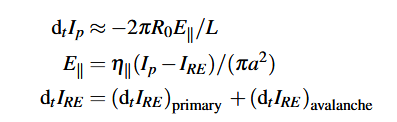

In [11]:
# Here we define the ODEs
def dYdt(t,Y,primary_sources=[1,1,1],iAvalanche=1,nD=1e-10,nNe=1e20):
    # Y[0] = Plasma Current [A]
    # Y[1] = RE current [A]
    # Y[2] = RE Kinetic Energy [J]
    # primary_sources = [iDreicer, iTritium, iCompton], 0 = off
    # iDreicer = 1 Classical; 2 = Hesslow NN
    # iAvalanche = 1 Rosenbluth-Putvinski * ntot/ne, 2 Simple RP, 3 = Hesslow, 0 = off
    
    Ip, Ir, Wkin = Y
    
    iDreicer, iTritium, iCompton = primary_sources
    
    # Prescribed Thermal Quench
    T = (T0 - Tf)* np.exp(-t/t0) + Tf # eV, Time-varying temperature
    # ZNe = getZbarTF(10, 20, SI2cgs(20*nNe*const.m_p,'Mass Density'), T)[0] # caluclate ionization level using LTE Thomas-Fermi model
    ZNe = getNeZ(T) # Using ADAS Coronal Eqm. Model
    ne = 1 * ni + 1 * nD + ZNe * nNe # Total free electron density, per cubic m, assumes hydrogenic species are fully ionized
    Zeff = (ni + nD + nNe * ZNe**2) / (ni + nD + nNe * ZNe) # Effective ionization of plasma
    ntot = ni + nD + 10 * nNe # Total free + bound electron density, per cubic m
    
    lnA = getCoulombLog(ne,T) # Coulomb logarithm
    eta = 0.51 * getTransSpitzerResistivity(lnA,T,Zeff) * 0.01 # Ohm-m
    Epar = eta*(Ip - Ir) / (np.pi * a**2 * k) # Parallel E-field [N/C]
    Ec = getConnorHastieField(ne,lnA) # Connor-Hastie Critical Field, [N/C]
    Ed = getDreicerField(ne,lnA,T) # [N/C] Dreicer Field
    E_star = Epar / Ec # Normalized field [-]
    
    
    # Primary Sources
    
    if iDreicer == 1:
        SD = getDreicerSource(E_star,ne,lnA,Zeff,T) # per m3 per s, Classical Dreicer
    elif iDreicer == 2:
        SD = getDreicerRateHesslow(ni,nNe,18,ZNe,Epar/Ed,T)
    else:
        SD = 0
    
    
    ST = getTritBetaDecay(0.5*ni,E_star)  # per m3 per s
    
    if T >= 2.6e3:
        SC = getComptonSource(E_star,ntot,'ARC-P') # Use Prompt Flux
    else:
        SC =  getComptonSource(E_star,ntot,'ARC-NP') # Use Non Prompt Flux
        
    # Total Primary Contribution
    S =  SD + iTritium * ST + iCompton * SC # per m3 per s
    j_primary = S * const.c * const.e # A/m**2/s
        
    # Avalanche
    if (iAvalanche == 0):
        Yav = 0;
    elif (iAvalanche == 1):
         Yav = (ntot/ne) * get_avalance_growth_rate_RP2(E_star,ne,0/R0,lnA,Zeff) # per second
    elif (iAvalanche == 2):
        Yav = 1 * get_avalance_growth_rate_RP2(E_star,ne,0/R0,lnA,Zeff) # per second
    elif (iAvalanche == 3): #Implement getHesslowAvalanchingRate 
     # Define arrays for species info, first element deuterium, second Neon (impurity)
        Z = np.array([1, 10])             # Max ionization of D and Ne
        nj = np.array([ni, nNe])          # Densities [m^-3]
        # trying to use interpolation here
        Zlow = int(np.floor(ZNe))
        Zhigh = int(np.ceil(ZNe))
        weight = ZNe - Zlow # interpolation weight

        # Creating 2 seperate arrays fo the low and high value
        Z0_low = np.array([1, Zlow])
        Z0_high = np.array([1, Zhigh])

        Y_low = getHesslowAvalanchingRate(E_star, Z, Z0_low, nj, T, element='Ne', B=Btor)
        Y_high = getHesslowAvalanchingRate(E_star, Z, Z0_high, nj, T, element='Ne', B=10)
        Yav = (1 - weight) * Y_low + weight * Y_high # set has the weighted average of the two
    
    dIpdt = -2 * np.pi * R0 * Epar / L # [A/s]
    dIrdt = j_primary * np.pi * a**2 + Yav * Ir # [A/s]
    if (E_star > 1):
        dWkindt = 2 * np.pi * R0 * Ir * Epar
    else:
        dWkindt = 0
    
    return [dIpdt, dIrdt, dWkindt]

# Solve

In [26]:
from scipy.integrate import solve_ivp
t = np.linspace(0,20e-3,10000) # times to solve at [s]
Ir0 = 1e4 # [A], Initial RE Current
iDreicer, iTritium, iCompton = 0, 0, 0 # Set Primary Sources
primary_sources=[iDreicer, iTritium, iCompton] # [iDreicer, iTritium, iCompton]


# hesslow avalanching
iAvalanche = 3 # Set Avalanche Source
sol = solve_ivp(dYdt, t_span=(0,max(t)),
                y0 = [I0,Ir0,0],
                t_eval=t,
                args=(primary_sources,iAvalanche,nD,nNe)) # Solve
# print(sol)

# original
iAvalanche = 1 # Set Avalanche Source 1 Rosenbluth-Putvinski * ntot/ne, 2 Simple RP,
sol2 = solve_ivp(dYdt, t_span=(0,max(t)),
                 y0 = [I0,Ir0,0],
                 t_eval=t,args=(primary_sources,iAvalanche,nD,nNe)) # Solve
# print(sol2)

# original
iAvalanche = 2 # Set Avalanche Source 1 Rosenbluth-Putvinski * ntot/ne, 2 Simple RP,
sol3 = solve_ivp(dYdt, t_span=(0,max(t)),
                 y0 = [I0,Ir0,0],
                 t_eval=t,
                 args=(primary_sources,iAvalanche,nD,nNe)) # Solve
# print(sol3)

# Show Solution

Here, we will plot $I_p$ and $I_{RE}$ as a function of time

Plateau Current Hesslow [MA] = 7.361
Plateau Current Rosenbluth-Putvinski [MA] = 7.369


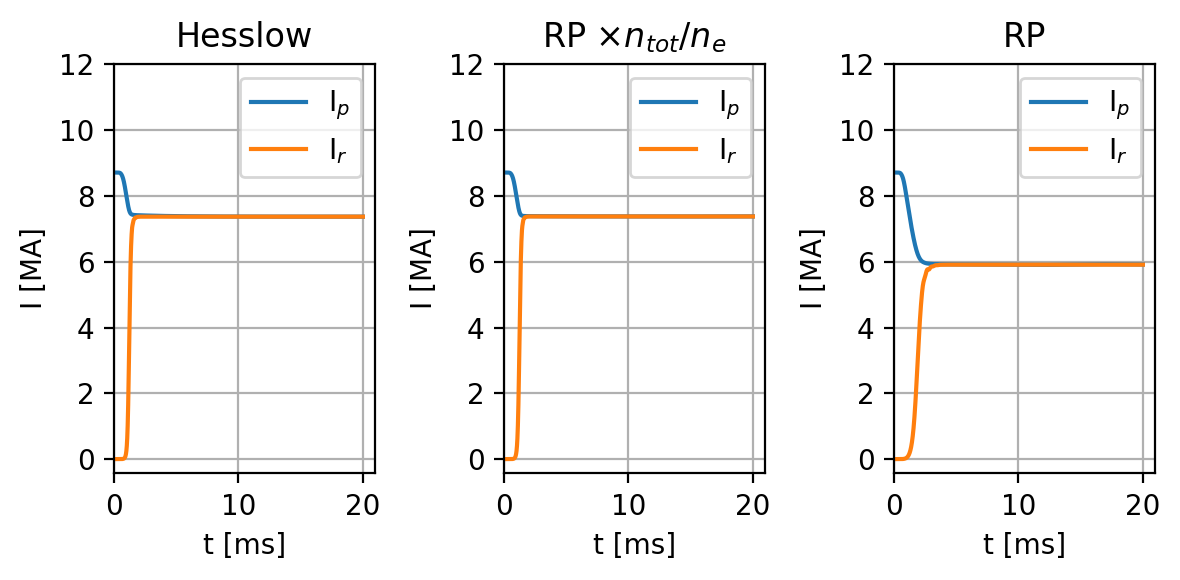

In [21]:
fig, axs = plt.subplots(1,3,figsize=(6,3),dpi=200,sharex=True)
# Hesslow Plot
axs[0].plot(sol.t*1e3,sol.y[0]/1e6,label='I$_p$')
axs[0].plot(sol.t*1e3,sol.y[1]/1e6,label='I$_r$')
axs[0].set_xlabel('t [ms]')
axs[0].set_ylabel('I [MA]')
axs[0].grid()
axs[0].set_yticks(np.arange(0,13,2))
axs[0].legend()
axs[0].set_xlim(xmin=0)
axs[0].set_title("Hesslow")

# Original Plot
axs[1].plot(sol2.t*1e3,sol2.y[0]/1e6,label='I$_p$')
axs[1].plot(sol2.t*1e3,sol2.y[1]/1e6,label='I$_r$')
axs[1].set_xlabel('t [ms]')
axs[1].set_ylabel('I [MA]')
axs[1].grid()
axs[1].set_yticks(np.arange(0,13,2))
axs[1].legend()
axs[1].set_xlim(xmin=0)
axs[1].set_title("RP $\\times n_{tot}/n_e$")

# Original Plot
axs[2].plot(sol3.t*1e3,sol3.y[0]/1e6,label='I$_p$')
axs[2].plot(sol3.t*1e3,sol3.y[1]/1e6,label='I$_r$')
axs[2].set_xlabel('t [ms]')
axs[2].set_ylabel('I [MA]')
axs[2].grid()
axs[2].set_yticks(np.arange(0,13,2))
axs[2].legend()
axs[2].set_xlim(xmin=0)
axs[2].set_title("RP")

#axs[0].legend()
print('Plateau Current Hesslow [MA] = %1.3f'%(sol.y[0][-1]/1e6))
print('Plateau Current Rosenbluth-Putvinski [MA] = %1.3f'%(sol2.y[0][-1]/1e6))
fig.tight_layout()


# Detailed Results

<>:70: SyntaxWarning: invalid escape sequence '\p'
<>:72: SyntaxWarning: invalid escape sequence '\p'
<>:82: SyntaxWarning: invalid escape sequence '\g'
<>:70: SyntaxWarning: invalid escape sequence '\p'
<>:72: SyntaxWarning: invalid escape sequence '\p'
<>:82: SyntaxWarning: invalid escape sequence '\g'
C:\Users\grace\AppData\Local\Temp\ipykernel_57540\3860752135.py:70: SyntaxWarning: invalid escape sequence '\p'
  axs[2,0].plot(t*1e3,E_star,label='$E_{\parallel}/E_{CH}$')
C:\Users\grace\AppData\Local\Temp\ipykernel_57540\3860752135.py:72: SyntaxWarning: invalid escape sequence '\p'
  axs[2,0].plot(t*1e3,Epar/Ed*1e5,label='$E_\parallel/E_D \\times 10^5$')
C:\Users\grace\AppData\Local\Temp\ipykernel_57540\3860752135.py:82: SyntaxWarning: invalid escape sequence '\g'
  axs[0,1].set_ylabel('$\gamma_{ava}  [s^{-1}]$')
C:\Users\grace\AppData\Local\Temp\ipykernel_57540\3860752135.py:91: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an 

Text(0.5, 56.08333333333332, 't [ms]')

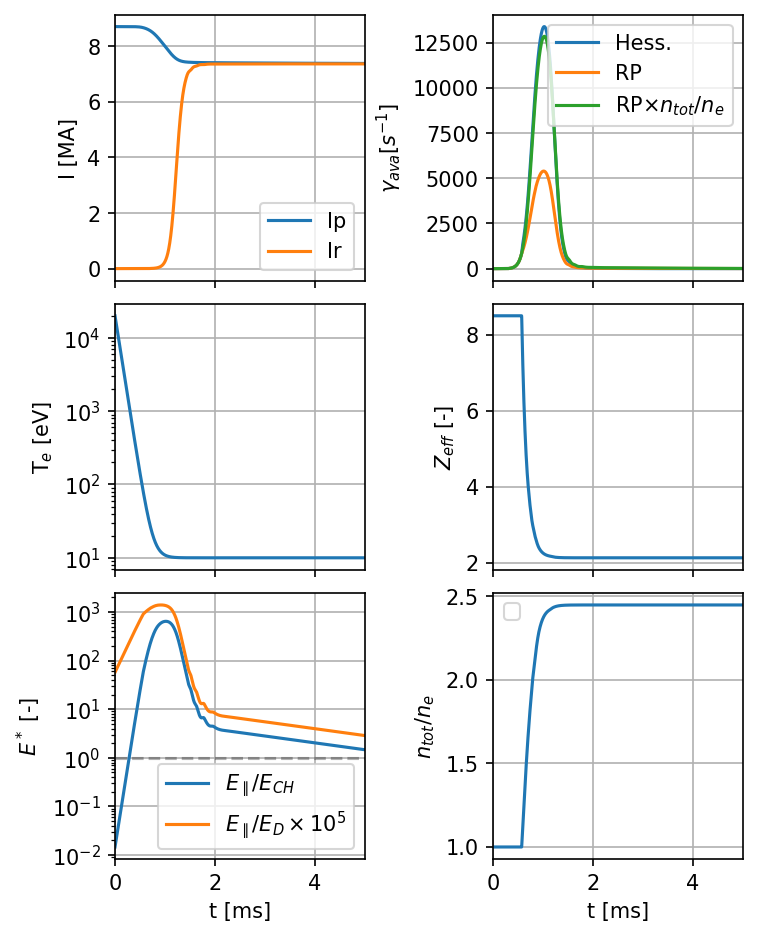

In [28]:
# Get Ip and Ir evolution from the ODE solution
Ip = sol.y[0]
Ir = sol.y[1]

# Calculate other relvant quantities
T = (T0 - Tf)* np.exp(-t/t0) + Tf # eV, Time-varying temperature
ZNe = getNeZ(T) # Using ADAS Coronal Eqm. Model
ne = 1 * ni + 1 * nD + ZNe * nNe # Total free electron density, per cubic m, assumes hydrogenic species are fully ionized
Zeff = (ni + nD + nNe * ZNe**2) / ne # Effective ionization of plasma
ntot = ni + nD + 10 * nNe # Total free + bound electron density, per cubic m
lnA = getCoulombLog(ne,T)
eta = 0.51 * getTransSpitzerResistivity(lnA,T,Zeff) * 0.01 # Ohm-m
Epar = eta*(Ip -Ir) / (np.pi * a**2 * k) # Parallel E-field [N/C]
Ec = getConnorHastieField(ne,lnA) # [N/C]
Ed = getDreicerField(ne,lnA,T) # [N/C]
E_star = Epar / Ec # Normalized field [-]
Wc = getCriticalRunawayEnergy(E_star) / const.eV # eV


# Primary Sources
if iDreicer == 1:
    SD = getDreicerSource(E_star,ne,lnA,Zeff,T) # per m3 per s, Classical Dreicer
elif iDreicer == 2:
    SD = getDreicerRateHesslow(ni,nNe,18,ZNe,Epar/Ed,T)
else:
    SD = np.zeros_like(E_star)

if iTritium:
    ST = getTritBetaDecay(0.5*ni,E_star)  # per m3 per s
else:
    ST = 0 * SD
if iCompton:
    SC =  getComptonSource(E_star,ntot,'ARC-P') 
    SC[np.where(T<2.6e3)] = 1e0 * getComptonSource(E_star[np.where(T<2.6e3)],ntot,'ARC-NP') 
else:
    SC = 0 * SD

# Secondary Sources
Yav_RP =  1 * get_avalance_growth_rate_RP2(E_star,ne,0/R0,lnA,Zeff) # per second
Yav = np.zeros_like(E_star)
for ii in range(E_star.shape[0]):
    Z = np.array([1, 10])             # Max ionization of D and Ne
    nj = np.array([ni, nNe])          # Densities [m^-3]
    # trying to use interpolation here
    Zlow = int(np.floor(ZNe[ii]))
    Zhigh = int(np.ceil(ZNe[ii]))
    weight = ZNe[ii] - Zlow # interpolation weight

    # Creating 2 seperate arrays fo the low and high value
    Z0_low = np.array([1, Zlow])
    Z0_high = np.array([1, Zhigh])


    Y_low = getHesslowAvalanchingRate(E_star[ii], Z, Z0_low, nj, T[ii], element='Ne', B=0)
    Y_high = getHesslowAvalanchingRate(E_star[ii], Z, Z0_high, nj, T[ii], element='Ne', B=0)
    Yav[ii] = (1 - weight) * Y_low + weight * Y_high # set has the weighted average of the two

############ Plot ##################
fig, axs = plt.subplots(3,2,sharex=True,figsize=(5,6),dpi=150)

axs[0,0].plot(t*1e3,Ip/1e6,label='Ip')
axs[0,0].plot(t*1e3,Ir/1e6,label='Ir')
axs[0,0].set_ylabel('I [MA]')
axs[0,0].legend()

axs[1,0].plot(t*1e3,T)
axs[1,0].set_ylabel('T$_e$ [eV]')
axs[1,0].set_yscale('log')

axs[2,0].plot(t*1e3,E_star,label='$E_{\parallel}/E_{CH}$')
axs[2,0].plot([0,t.max()*1e3],[1,1],'--',color='k',alpha=0.3)
axs[2,0].plot(t*1e3,Epar/Ed*1e5,label='$E_\parallel/E_D \\times 10^5$')
axs[2,0].set_ylabel('$E^*$ [-]')
axs[2,0].set_yscale('log')
axs[2,0].legend()



axs[0,1].plot(t*1e3,Yav,label='Hess.')
axs[0,1].plot(t*1e3,Yav_RP,label='RP')
axs[0,1].plot(t*1e3,Yav_RP*(ntot/ne),label='RP$\\times n_{tot}/n_e$')
axs[0,1].set_ylabel('$\gamma_{ava}  [s^{-1}]$')
# axs[0,1].set_yscale('log')
axs[0,1].legend()

axs[1,1].plot(t*1e3,Zeff)
axs[1,1].set_ylabel('$Z_{eff}$ [-]')

axs[2,1].plot(t*1e3,ntot/ne)
axs[2,1].set_ylabel('$n_{tot}/n_e$')
axs[2,1].legend()


fig.tight_layout(pad=0.5)

for i in range(axs.shape[0]):
    for j in range(axs.shape[1]):
        axs[i,j].grid()
        axs[i,j].set_xlim([0,5])
        
axs[-1,0].set_xlabel('t [ms]')    
axs[-1,1].set_xlabel('t [ms]')  



# Show result vs Iseed

In [22]:
seed_vals = np.array([1e-3,1e-2,1,1e2,1e4]) # [A]
Iplat = np.zeros_like(seed_vals)
Iplat_RP1 = np.zeros_like(seed_vals)
Iplat_RP2 = np.zeros_like(seed_vals)
t = np.linspace(0,20e-3,4000) # times to solve at [s]

for ii in range(seed_vals.shape[0]):
    # testing hesslow avalanching
    iDreicer, iTritium, iCompton = 0, 0, 0 # Set Primary Sources
    Ir0 = seed_vals[ii] # [A], Initial RE Current
    primary_sources=[iDreicer, iTritium, iCompton] # [iDreicer, iTritium, iCompton]
    sol = solve_ivp(dYdt, t_span=(0,max(t)), y0 = [I0,Ir0,0],t_eval=t,args=(primary_sources,3,nD,nNe)) # Solve
    Iplat[ii] = sol.y[0][-1]
    sol = solve_ivp(dYdt, t_span=(0,max(t)), y0 = [I0,Ir0,0],t_eval=t,args=(primary_sources,2,nD,nNe)) # Solve
    Iplat_RP1[ii] = sol.y[0][-1]
    sol = solve_ivp(dYdt, t_span=(0,max(t)), y0 = [I0,Ir0,0],t_eval=t,args=(primary_sources,1,nD,nNe)) # Solve
    Iplat_RP2[ii] = sol.y[0][-1]
    

Text(0.5, 1.0, '$n_{Ne} = $1.5e+20 [per cubic m]')

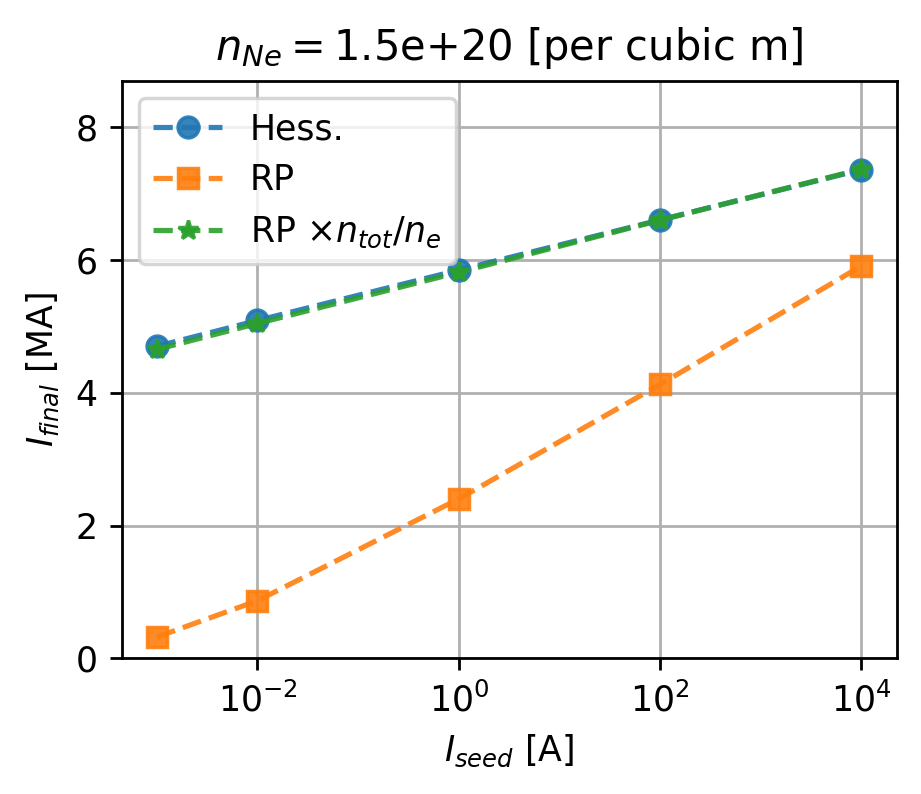

In [23]:
fig, axs = plt.subplots(1,1,dpi=250,figsize=(4,3))
axs.plot(seed_vals,Iplat/1e6,'--o',label='Hess.',alpha=0.9)
axs.plot(seed_vals,Iplat_RP1/1e6,'--s',label='RP',alpha=0.9)
axs.plot(seed_vals,Iplat_RP2/1e6,'--*',label='RP $\\times n_{tot}/n_e$',alpha=0.9)
axs.set_xscale('log')
axs.grid()
axs.set_ylim([0,8.7])
axs.legend()
axs.set_ylabel('$I_{final}$ [MA]')
axs.set_xlabel('$I_{seed}$ [A]')
axs.set_title('$n_{Ne} = $' + str(nNe) + ' [per cubic m]')